In [ ]:
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

In [ ]:
from google.colab import files
uploaded = files.upload()

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

Saving dataset_phishing.csv to dataset_phishing.csv


In [ ]:
# Nettoyage des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})


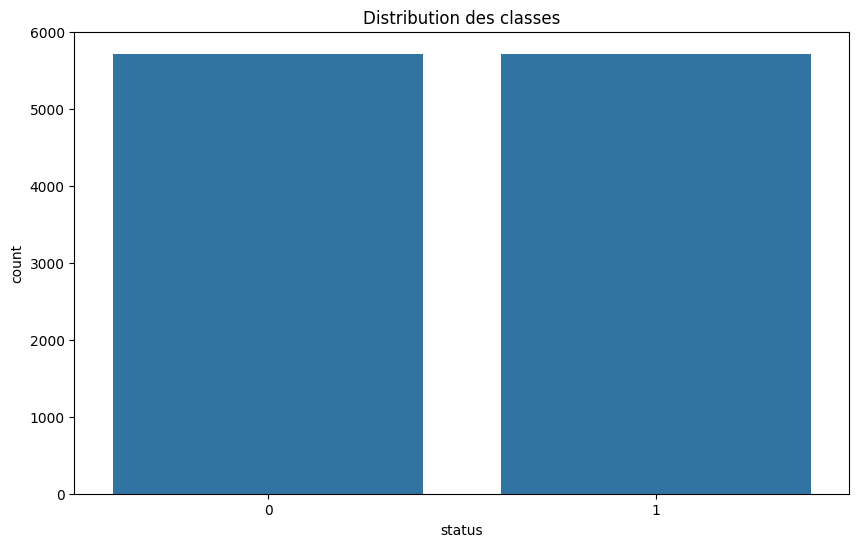

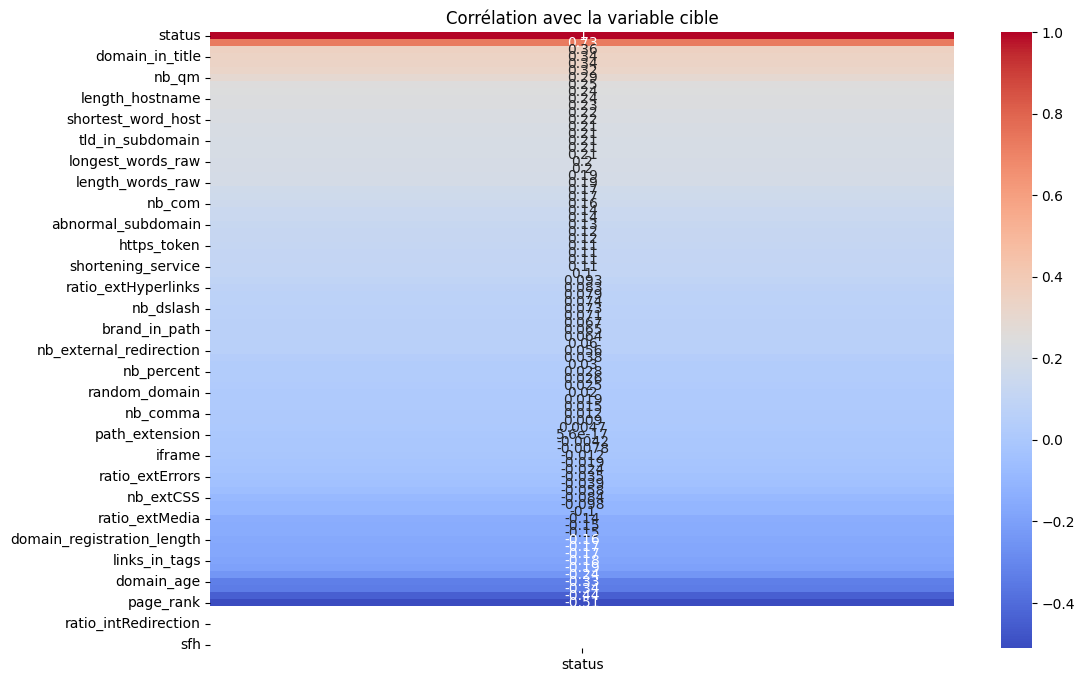

In [ ]:
# Étape 2: Analyse exploratoire (EDA)
# ---------------------------------------------------
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

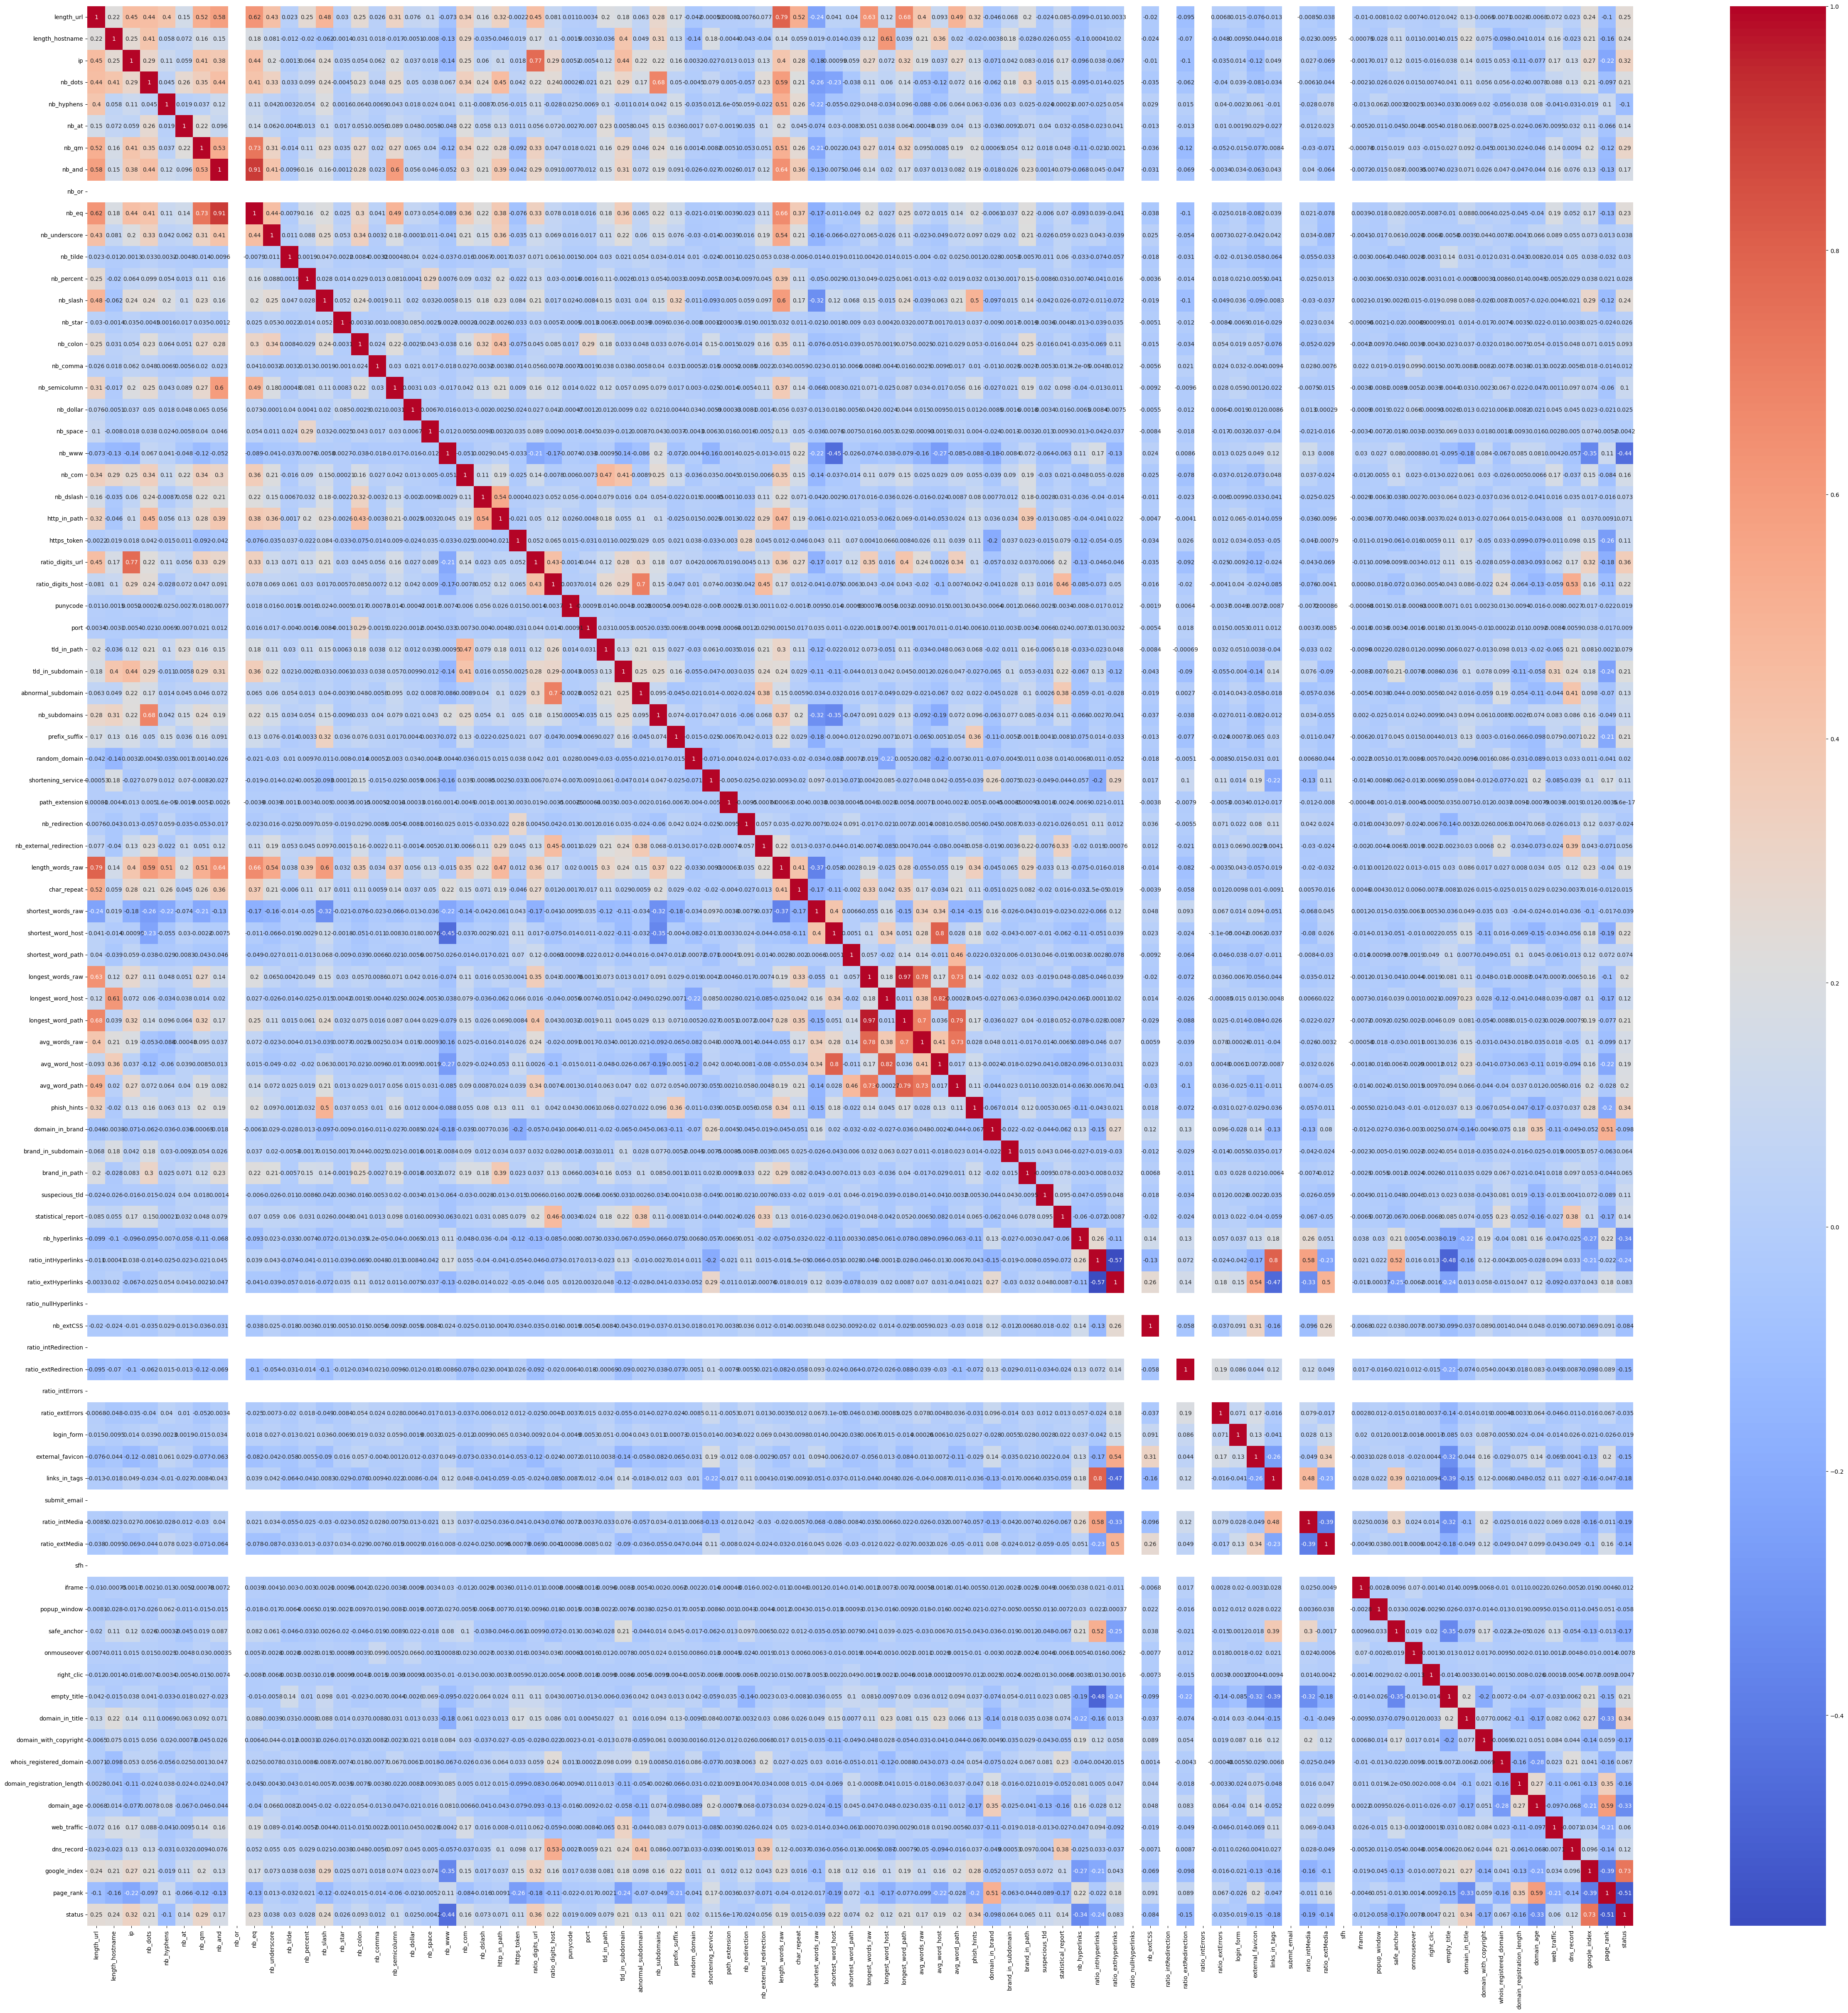

In [ ]:
plt.figure(figsize=(60,60))
color = plt.get_cmap('viridis').copy()   # default color
color.set_bad('lightblue')
sns.heatmap(df.corr(),
            annot=True, cmap='coolwarm')
plt.savefig('heatmap')
plt.show()

In [ ]:
# Étape 3: Préparation des données pour le CNN
# ---------------------------------------------------
# Séparation features/target
X = df.drop(columns=['status']).values
y = df['status'].values

In [ ]:
# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
# Redimensionnement pour CNN 1D
X = X.reshape(X.shape[0], X.shape[1], 1)

In [ ]:
# Split des données
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   test_size=0.2,
                                                   random_state=42,
                                                   stratify=y)

In [ ]:
import tensorflow as tf

In [ ]:
# Étape 4: Architecture du CNN
# ---------------------------------------------------
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.3),

        Conv1D(128, 3, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.4),

        Flatten(),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
                 loss='binary_crossentropy',
                 metrics=['accuracy',
                         tf.keras.metrics.Precision(name='precision'),
                         tf.keras.metrics.Recall(name='recall')])
    return model

In [ ]:
# Construction du modèle
model = build_cnn((X_train.shape[1], 1))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 85, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 85, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 40, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 40, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2560)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         655,616 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 682,625 (2.60 MB)

 Trainable params: 681,729 (2.60 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# Étape 5: Entraînement avec gestion de l'overfitting
# ---------------------------------------------------
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

history = model.fit(X_train, y_train,
                   epochs=100,
                   batch_size=64,
                   validation_split=0.2,
                   callbacks=callbacks,
                   class_weight={0: 1, 1: 1.2})  # Ajustement des poids de classe

Epoch 1/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7864 - loss: 0.5796 - precision: 0.7877 - recall: 0.7846

115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step - accuracy: 0.7873 - loss: 0.5772 - precision: 0.7885 - recall: 0.7858 - val_accuracy: 0.6884 - val_loss: 0.5042 - val_precision: 0.9835 - val_recall: 0.3876
Epoch 2/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8950 - loss: 0.2863 - precision: 0.8810 - recall: 0.9151

115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.8951 - loss: 0.2862 - precision: 0.8811 - recall: 0.9151 - val_accuracy: 0.9071 - val_loss: 0.3032 - val_precision: 0.9747 - val_recall: 0.8371
Epoch 3/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9081 - loss: 0.2546 - precision: 0.9001 - recall: 0.9163

115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.9082 - loss: 0.2547 - precision: 0.9001 - recall: 0.9164 - val_accuracy: 0.9295 - val_loss: 0.2106 - val_precision: 0.9615 - val_recall: 0.8958
Epoch 4/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9179 - loss: 0.2379 - precision: 0.9154 - recall: 0.9223

115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.9178 - loss: 0.2379 - precision: 0.9153 - recall: 0.9224 - val_accuracy: 0.9410 - val_loss: 0.1592 - val_precision: 0.9552 - val_recall: 0.9262
Epoch 5/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9228 - loss: 0.2164 - precision: 0.9196 - recall: 0.9248

...

115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.9480 - loss: 0.1535 - precision: 0.9414 - recall: 0.9543 - val_accuracy: 0.9557 - val_loss: 0.1292 - val_precision: 0.9585 - val_recall: 0.9533
Epoch 18/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9503 - loss: 0.1422 - precision: 0.9463 - recall: 0.9551

115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9503 - loss: 0.1423 - precision: 0.9463 - recall: 0.9551 - val_accuracy: 0.9546 - val_loss: 0.1276 - val_precision: 0.9554 - val_recall: 0.9544
Epoch 19/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9420 - loss: 0.1731 - precision: 0.9326 - recall: 0.9516 - val_accuracy: 0.9563 - val_loss: 0.1332 - val_precision: 0.9556 - val_recall: 0.9577
Epoch 20/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.9459 - loss: 0.1513 - precision: 0.9434 - recall: 0.9492 - val_accuracy: 0.9541 - val_loss: 0.1293 - val_precision: 0.9584 - val_recall: 0.9501
Epoch 21/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9438 - loss: 0.1532 - precision: 0.9393 - recall: 0.9486

115/115 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.9439 - loss: 0.1532 - precision: 0.9394 - recall: 0.9487 - val_accuracy: 0.9546 - val_loss: 0.1263 - val_precision: 0.9615 - val_recall: 0.9479
Epoch 22/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9547 - loss: 0.1388 - precision: 0.9500 - recall: 0.9586

115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9546 - loss: 0.1388 - precision: 0.9500 - recall: 0.9586 - val_accuracy: 0.9574 - val_loss: 0.1252 - val_precision: 0.9617 - val_recall: 0.9533
Epoch 23/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9539 - loss: 0.1237 - precision: 0.9485 - recall: 0.9598 - val_accuracy: 0.9568 - val_loss: 0.1266 - val_precision: 0.9576 - val_recall: 0.9566
Epoch 24/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9521 - loss: 0.1398 - precision: 0.9482 - recall: 0.9577

115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.9521 - loss: 0.1398 - precision: 0.9482 - recall: 0.9576 - val_accuracy: 0.9568 - val_loss: 0.1217 - val_precision: 0.9637 - val_recall: 0.9501
Epoch 25/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.9557 - loss: 0.1326 - precision: 0.9552 - recall: 0.9551 - val_accuracy: 0.9568 - val_loss: 0.1287 - val_precision: 0.9537 - val_recall: 0.9609
Epoch 26/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9521 - loss: 0.1442 - precision: 0.9492 - recall: 0.9570 - val_accuracy: 0.9535 - val_loss: 0.1290 - val_precision: 0.9583 - val_recall: 0.9490
Epoch 27/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9535 - loss: 0.1319 - precision: 0.9511 - recall: 0.9584 - val_accuracy: 0.9574 - val_loss: 0.1277 - val_precision: 0.9657 - val_recall: 0.9490
Epoch 28/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.9533 - loss: 0.1386 - precision: 0.9520 - recall: 0.9540 - val_accuracy: 0.9601 - val_loss: 

In [ ]:
# Évaluation finale
y_pred = (model.predict(X_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred))

72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      1143
           1       0.95      0.96      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286

